# 多分类神经网络在量子关联分类中的应用研究

Research on the application of multi-classification neural network in quantum correlation classification (MCNN-QCC)

## 概要

本课题将通过知名深度学习框架Pytorch搭建神经网络，分析QCC数据集，观察训练误差和验证误差随训练代数提高的变化。

徐浩轩 集美大学 2023-12

GitHub：[ollyhsu/MCNN-QCC](https://github.com/ollyhsu/MCNN-QCC)


# 环境准备

## 下载Pytorch

打开浏览器，访问 [PyTorch官方网站](https://pytorch.org/)

在官网首页，你会看到一个“Get Started”（开始使用）的按钮或类似的链接，点击它

接下来，你可能需要选择一些选项，比如选择你的操作系统、安装方式（例如pip或conda）、Python版本等。根据你的需求进行选择，并点击相关选项

完成上述步骤后，网站会为你生成一个相应的安装命令。复制这个命令，它会类似于：

```bash
pip3 install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
```

## 验证安装成功

你可以运行以下代码单元来验证PyTorch的安装是否成功，并检查CUDA是否可用以及CUDA的版本：

In [1]:
import torch

# 检查CUDA是否可用
cuda_available = torch.cuda.is_available()
print("CUDA Available: ", cuda_available)

if cuda_available:
    # 打印CUDA设备数量
    device_count = torch.cuda.device_count()
    print("CUDA Device Count: ", device_count)

    # 打印CUDA版本
    cuda_version = torch.version.cuda
    print("CUDA Version: ", cuda_version)

CUDA Available:  True
CUDA Device Count:  1
CUDA Version:  12.1


运行此代码单元后，如果你看到输出显示CUDA可用、设备数量以及CUDA版本，则说明PyTorch已经成功安装，并且CUDA也可用

# 数据集准备

## 生成数据集

运行`genDataset.py` 文件，生成数据集至 `dataset` 目录下

数据集标签说明：

`0` for separable states, `1` for two-separable states, `2` for entangled states

## 导入数据集

In [2]:
import torch  # 导入pytorch
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

# 准备数据
train_mixes = np.load('dataset/qcc_train_set_mixes.npy')
train_labels = np.load('dataset/qcc_train_set_labels.npy')
test_mixes = np.load('dataset/qcc_test_set_mixes.npy')
test_labels = np.load('dataset/qcc_test_set_labels.npy')

# Convert to PyTorch tensors
train_mixes_tensor = torch.tensor(train_mixes, dtype=torch.float32)
train_labels_tensor = torch.tensor(train_labels, dtype=torch.long)

test_mixes_tensor = torch.tensor(test_mixes, dtype=torch.float32)
test_labels_tensor = torch.tensor(test_labels, dtype=torch.long)

# Extract real and imaginary parts
train_mixes_real = train_mixes_tensor[:, :, :, 0]
train_mixes_imag = train_mixes_tensor[:, :, :, 1]

test_mixes_real = test_mixes_tensor[:, :, :, 0]
test_mixes_imag = test_mixes_tensor[:, :, :, 1]

# Complex tensor
train_mixes_complex = torch.stack((train_mixes_real, train_mixes_imag), dim=1)
test_mixes_complex = torch.stack((test_mixes_real, test_mixes_imag), dim=1)

# Create PyTorch datasets
train_dataset = TensorDataset(train_mixes_complex, train_labels_tensor)
test_dataset = TensorDataset(test_mixes_complex, test_labels_tensor)

train_dataloader = DataLoader(train_dataset, batch_size=100, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=100, shuffle=True)

# print("Train Mixes Tensor Shape: ", train_mixes_tensor.shape)
# print("Train Labels Tensor Shape: ", train_labels_tensor.shape)
# print("Test Mixes Tensor Shape: ", test_mixes_tensor.shape)
# print("Test Labels Tensor Shape: ", test_labels_tensor.shape)

print("Train Mixes ComplexShape: ", train_mixes_complex.shape)
print("Test Mixes ComplexShape: ", test_mixes_complex.shape)

print("Train Dataset Size: ", len(train_dataset))
print("Test Dataset Size: ", len(test_dataset))
print("Train Dataloader Size: ", len(train_dataloader))
print("Test Dataloader Size: ", len(test_dataloader))

Train Mixes ComplexShape:  torch.Size([48000, 2, 8, 8])
Test Mixes ComplexShape:  torch.Size([12000, 2, 8, 8])
Train Dataset Size:  48000
Test Dataset Size:  12000
Train Dataloader Size:  480
Test Dataloader Size:  120


# 全连接神经网络模型

## 全连接神经网络

神经网络的输入为 2 * 8 * 8 = 128 的张量

第一个隐含层包含256个神经元

第二个隐含层包含多128个神经元

第三个隐含层包含64个神经元

输出层输出3个结果，对应数据集量子态的3种分类

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# 定义四层全连接神经网络模型
class FCNNModel(nn.Module):
    def __init__(self):
        super(FCNNModel, self).__init__()
        self.fc1 = nn.Linear(128, 256)  # 第一个隐藏层，输入大小为128，输出大小为256
        self.fc2 = nn.Linear(256, 128)  # 第二个隐藏层，输入大小为256，输出大小为128
        self.fc3 = nn.Linear(128, 64)  # 第三个隐藏层，输入大小为128，输出大小为64
        self.fc4 = nn.Linear(64, 3)  # 输出层，输入大小为64，输出大小为3（类别数量）

    def forward(self, x):
        x = torch.flatten(x, 1)  # 将输入展平成一维张量
        x = F.relu(self.fc1(x))  # 第一个隐藏层的激活函数为ReLU
        x = F.relu(self.fc2(x))  # 第二个隐藏层的激活函数为ReLU
        x = F.relu(self.fc3(x))  # 第三个隐藏层的激活函数为ReLU
        x = self.fc4(x)  # 输出层不需要激活函数，因为后面会使用交叉熵损失函数
        return x

In [4]:
# from tqdm import tqdm
import torch.optim as optim

# 实例化模型
model_fc = FCNNModel()

# 定义损失函数和优化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_fc.parameters(), lr=0.001)

# 训练模型
num_epochs = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_fc.to(device)
model_fc.train()

# 将每次训练的训练误差和测试误差存储在这两个列表里，后面绘制误差变化折线图用
fc_train_losses, fc_test_losses, fc_train_accs, fc_test_accs = [], [], [], []

print('Start training')
for epoch in range(num_epochs):
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    # for inputs, labels in tqdm(train_dataloader, desc=f'Epoch {epoch + 1}/{num_epochs}', leave=False):
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_fc(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    # 每次学完一遍数据集，都进行以下测试操作
    model_fc.eval()
    test_loss = 0.0
    correct_test = 0
    total_test = 0
    with torch.no_grad():
        # for inputs, labels in tqdm(test_dataloader, desc='Test', leave=False):
        for inputs, labels in test_dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_fc(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(train_dataset)
    train_acc = 100. * correct_train / total_train
    test_loss = test_loss / len(test_dataset)
    test_acc = 100. * correct_test / total_test

    # 恢复Dropout
    model_fc.train()

    # 将训练误差和测试误差存在两个列表里，后面绘制误差变化折线图用
    fc_train_losses.append(train_loss)
    fc_test_losses.append(test_loss)
    fc_train_accs.append(train_acc)
    fc_test_accs.append(test_acc)

    print("Number: {}/{}  ".format(epoch + 1, num_epochs),
          "Train Loss: {:.4f}  ".format(train_loss),
          "Test Loss: {:.4f}  ".format(test_loss),
          "Model Test Accuracy: {:.3f}%".format(test_acc))

print('Finished Training')

Start training
Number: 1/10   Train Loss: 0.1741   Test Loss: 0.0636   Model Test Accuracy: 98.300%
Number: 2/10   Train Loss: 0.0584   Test Loss: 0.0495   Model Test Accuracy: 98.792%
Number: 3/10   Train Loss: 0.0520   Test Loss: 0.0493   Model Test Accuracy: 98.658%
Number: 4/10   Train Loss: 0.0493   Test Loss: 0.0446   Model Test Accuracy: 98.817%
Number: 5/10   Train Loss: 0.0470   Test Loss: 0.0502   Model Test Accuracy: 98.725%
Number: 6/10   Train Loss: 0.0446   Test Loss: 0.0489   Model Test Accuracy: 98.892%
Number: 7/10   Train Loss: 0.0443   Test Loss: 0.0491   Model Test Accuracy: 98.742%
Number: 8/10   Train Loss: 0.0434   Test Loss: 0.0476   Model Test Accuracy: 98.842%
Number: 9/10   Train Loss: 0.0438   Test Loss: 0.0424   Model Test Accuracy: 98.917%
Number: 10/10   Train Loss: 0.0414   Test Loss: 0.0442   Model Test Accuracy: 98.992%
Finished Training


In [5]:
# 保存模型
torch.save(model_fc.state_dict(), 'models/model_fc.pth', _use_new_zipfile_serialization=False)

### 验证模型效果

绘制训练误差和测试误差随学习次数增加的变化

In [6]:
import os
import matplotlib.pyplot as plt

%matplotlib inline
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

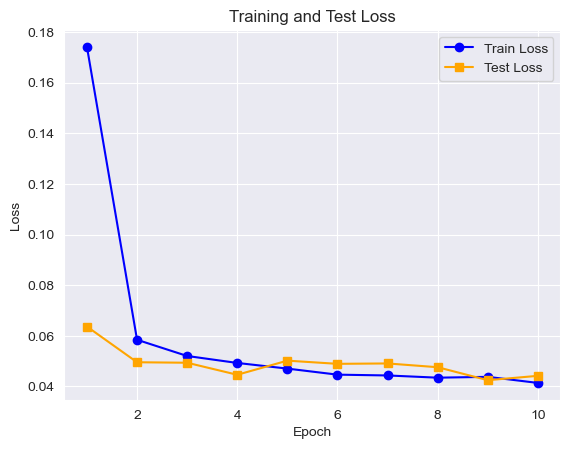

In [7]:
# 训练次数
epochs = range(1, len(fc_train_losses) + 1)

# 绘制训练误差和测试误差随学习次数增加的变化曲线
# plt.figure(figsize=(10, 5))
plt.plot(epochs, fc_train_losses, label='Train Loss', color='blue', marker='o')
plt.plot(epochs, fc_test_losses, label='Test Loss', color='orange', marker='s')

# 添加标签和标题
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Test Loss')
plt.legend()
plt.grid(True)

# 设置 x 轴刻度为每个 epoch 单位
# plt.xticks(range(1, len(fc_train_losses) + 1))

plt.show()

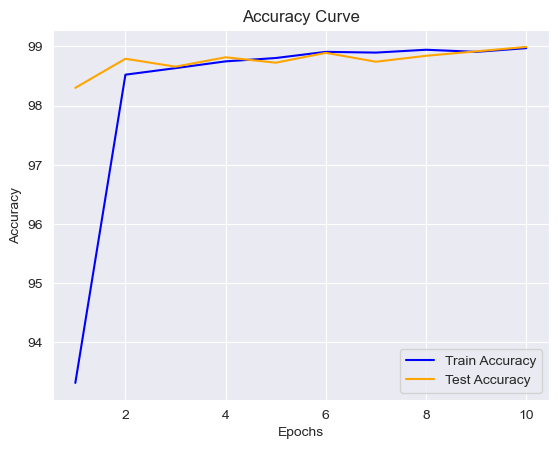

In [8]:
# 训练次数
epochs = range(1, len(fc_train_losses) + 1)

# 绘制准确率曲线图
plt.plot(epochs, fc_train_accs, label='Train Accuracy', color='blue')
plt.plot(epochs, fc_test_accs, label='Test Accuracy', color='orange')

# 添加标签和标题
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy Curve')
plt.legend()
plt.grid(True)

# 显示图像
plt.show()

In [9]:
# 加载模型
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_fc = FCNNModel()
model_fc.load_state_dict(torch.load('models/model_fc.pth', map_location=device))
model_fc.to(device)

FCNNModel(
  (fc1): Linear(in_features=128, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=64, bias=True)
  (fc4): Linear(in_features=64, out_features=3, bias=True)
)

In [10]:
# 初始化混淆矩阵和类别分类列表
label_dic = {0: 'separable states', 1: 'two-separable states', 2: 'entangled states'}
num_classes = len(label_dic)
conf_matrix = np.zeros((num_classes, num_classes))
class_correct = list(0. for i in range(num_classes))
class_total = list(0. for i in range(num_classes))

# 将模型设置为评估模式
model_fc.eval()

# 在测试集上进行测试
with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model_fc(inputs)
        _, predicted = torch.max(outputs, 1)
        c = (predicted == labels).squeeze()

        for i in range(len(labels)):
            label = labels[i]
            prediction = predicted[i]
            conf_matrix[label][prediction] += 1
            class_correct[label] += c[i].item()
            class_total[label] += 1

# 计算混淆矩阵的百分比
conf_matrix_percent_fc = conf_matrix / np.sum(conf_matrix, axis=1, keepdims=True)

# 计算每个类别的准确率
class_accuracy_fc = [100 * class_correct[i] / class_total[i] if class_total[i] > 0 else 0 for i in range(num_classes)]

# 计算精确率、召回率和 F1 值
precision_fc = [conf_matrix[i][i] / np.sum(conf_matrix[:, i]) if np.sum(conf_matrix[:, i]) > 0 else 0 for i in
                range(num_classes)]
recall_fc = [conf_matrix[i][i] / np.sum(conf_matrix[i, :]) if np.sum(conf_matrix[i, :]) > 0 else 0 for i in
             range(num_classes)]
f1_fc = [
    2 * precision_fc[i] * recall_fc[i] / (precision_fc[i] + recall_fc[i]) if precision_fc[i] + recall_fc[i] > 0 else 0
    for i in range(num_classes)]

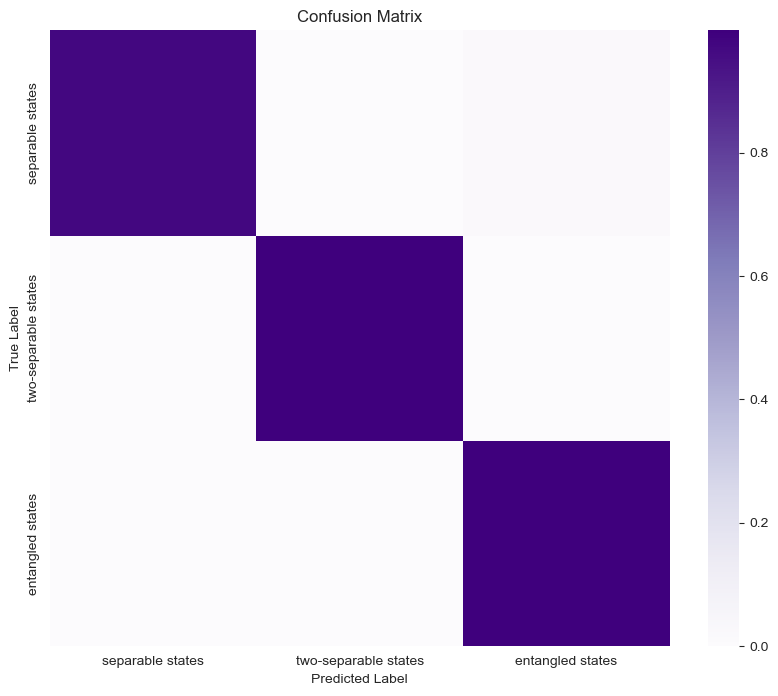

In [11]:
import seaborn as sns

# 绘制混淆矩阵
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_percent_fc, annot=False, cmap='Purples', fmt=".2f", xticklabels=label_dic.values(),
            yticklabels=label_dic.values())
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

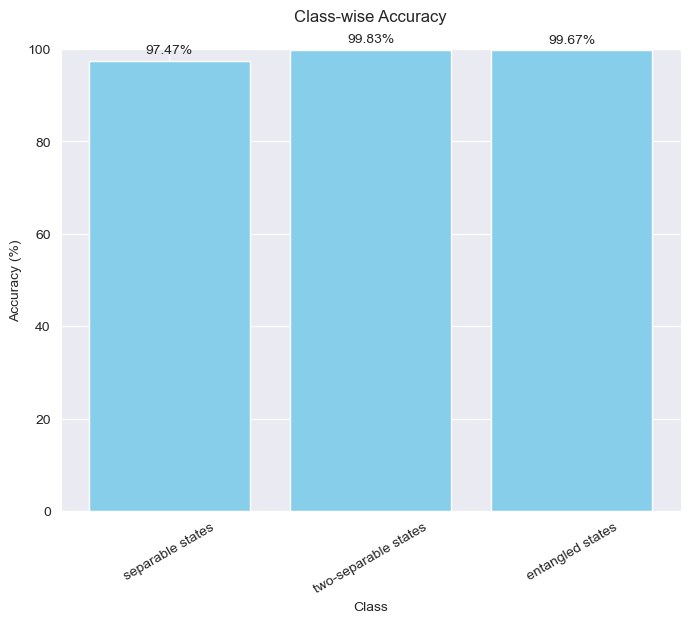

In [12]:
plt.figure(figsize=(8, 6))
bars = plt.bar(label_dic.values(), class_accuracy_fc, color='skyblue')

# 在每个条形上方添加文本标签
for i, acc in enumerate(class_accuracy_fc):
    plt.text(i, acc + 1, f'{acc:.2f}%', ha='center', va='bottom')

plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.title('Class-wise Accuracy', pad=20)
plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.show()

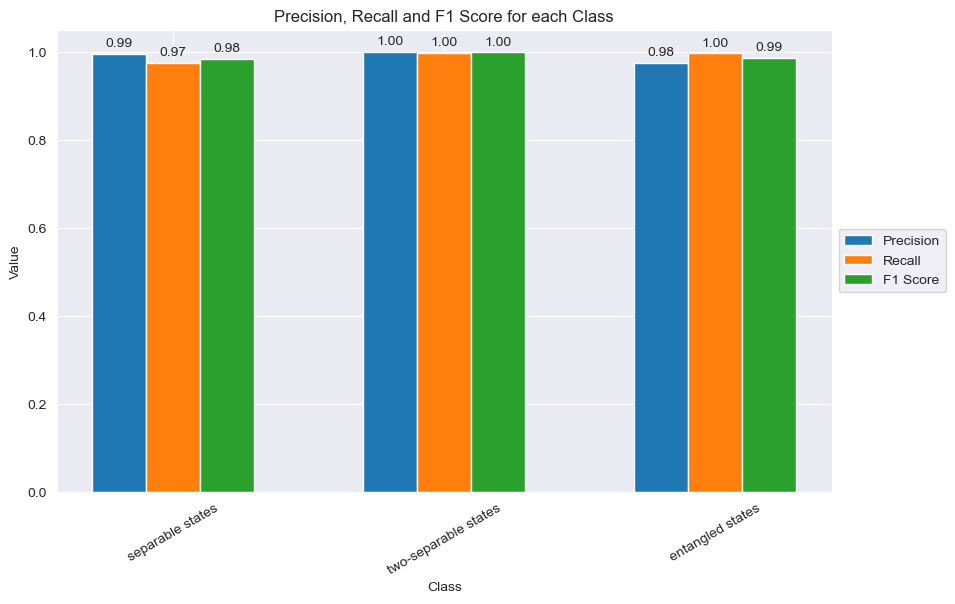

In [13]:
# 绘制精确率、召回率和 F1 值的条形图
x = np.arange(num_classes)
width = 0.2
label_dic = {0: 'separable states', 1: 'two-separable states', 2: 'entangled states'}
fig, ax = plt.subplots(figsize=(10, 6))
bars_precision = ax.bar(x - width, precision_fc, width, label='Precision')
bars_recall = ax.bar(x, recall_fc, width, label='Recall')
bars_f1 = ax.bar(x + width, f1_fc, width, label='F1 Score')

ax.set_xlabel('Class')
ax.set_ylabel('Value')
ax.set_title('Precision, Recall and F1 Score for each Class')
ax.set_xticks(x)
ax.set_xticklabels(label_dic.values(), rotation=30)


# 添加数值标签
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate('%.2f' % height,
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')


autolabel(bars_precision)
autolabel(bars_recall)
autolabel(bars_f1)
# 移动图例到右边
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

## 采用Dropout防止过拟合

In [14]:
import torch
import torch.nn as nn


class FCNNModelWithDropout(nn.Module):
    def __init__(self):
        super(FCNNModelWithDropout, self).__init__()
        self.fc1 = nn.Linear(8 * 8 * 2, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, 3)
        self.dropout = nn.Dropout(p=0.3)  # 添加 Dropout 层，p 参数表示丢弃概率

    def forward(self, x):
        x = x.view(-1, 8 * 8 * 2)  # 展平输入数据
        x = F.relu(self.fc1(x))
        x = self.dropout(x)  # 在第一个全连接层后添加 Dropout
        x = F.relu(self.fc2(x))
        x = self.dropout(x)  # 在第二个全连接层后添加 Dropout
        x = F.relu(self.fc3(x))
        x = self.dropout(x)  # 在第三个全连接层后添加 Dropout
        x = self.fc4(x)
        return x

In [15]:
# from tqdm import tqdm
import torch.optim as optim

# 实例化模型
model_fcd = FCNNModelWithDropout()

# 定义损失函数和优化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_fcd.parameters(), lr=0.001)

# 训练模型
num_epochs = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_fcd.to(device)
model_fcd.train()

# 将每次训练的训练误差和测试误差存储在这两个列表里，后面绘制误差变化折线图用
fcd_train_losses, fcd_test_losses, fcd_train_accs, fcd_test_accs = [], [], [], []

print('Start training')
for epoch in range(num_epochs):
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    # for inputs, labels in tqdm(train_dataloader, desc=f'Epoch {epoch + 1}/{num_epochs}', leave=False):
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_fcd(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    # 每次学完一遍数据集，都进行以下测试操作
    model_fcd.eval()
    test_loss = 0.0
    correct_test = 0
    total_test = 0
    with torch.no_grad():
        # for inputs, labels in tqdm(test_dataloader, desc='Test', leave=False):
        for inputs, labels in test_dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_fcd(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(train_dataset)
    train_acc = 100. * correct_train / total_train
    test_loss = test_loss / len(test_dataset)
    test_acc = 100. * correct_test / total_test

    # 恢复Dropout
    model_fcd.train()

    # 将训练误差和测试误差存在两个列表里，后面绘制误差变化折线图用
    fcd_train_losses.append(train_loss)
    fcd_test_losses.append(test_loss)
    fcd_train_accs.append(train_acc)
    fcd_test_accs.append(test_acc)

    print("Number: {}/{}  ".format(epoch + 1, num_epochs),
          "Train Loss: {:.4f}  ".format(train_loss),
          "Test Loss: {:.4f}  ".format(test_loss),
          "Model Test Accuracy: {:.3f}%".format(test_acc))

print('Finished Training')

Start training
Number: 1/10   Train Loss: 0.2104   Test Loss: 0.0568   Model Test Accuracy: 98.400%
Number: 2/10   Train Loss: 0.0724   Test Loss: 0.0483   Model Test Accuracy: 98.700%
Number: 3/10   Train Loss: 0.0612   Test Loss: 0.0453   Model Test Accuracy: 98.783%
Number: 4/10   Train Loss: 0.0554   Test Loss: 0.0429   Model Test Accuracy: 98.892%
Number: 5/10   Train Loss: 0.0544   Test Loss: 0.0439   Model Test Accuracy: 98.850%
Number: 6/10   Train Loss: 0.0549   Test Loss: 0.0410   Model Test Accuracy: 98.992%
Number: 7/10   Train Loss: 0.0509   Test Loss: 0.0410   Model Test Accuracy: 98.983%
Number: 8/10   Train Loss: 0.0497   Test Loss: 0.0406   Model Test Accuracy: 99.042%
Number: 9/10   Train Loss: 0.0486   Test Loss: 0.0408   Model Test Accuracy: 99.058%
Number: 10/10   Train Loss: 0.0492   Test Loss: 0.0388   Model Test Accuracy: 99.033%
Finished Training


In [16]:
# 保存模型
torch.save(model_fcd.state_dict(), 'models/model_fcd.pth', _use_new_zipfile_serialization=False)

### 验证模型效果

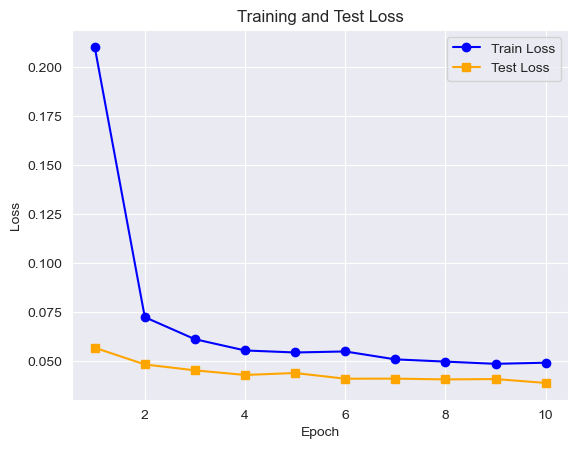

In [17]:
# 训练次数
epochs = range(1, len(fcd_train_losses) + 1)

# 绘制训练误差和测试误差随学习次数增加的变化曲线
# plt.figure(figsize=(10, 5))
plt.plot(epochs, fcd_train_losses, label='Train Loss', color='blue', marker='o')
plt.plot(epochs, fcd_test_losses, label='Test Loss', color='orange', marker='s')

# 添加标签和标题
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Test Loss')
plt.legend()
plt.grid(True)

# 设置 x 轴刻度为每个 epoch 单位
# plt.xticks(range(1, len(fc_train_losses) + 1))

plt.show()

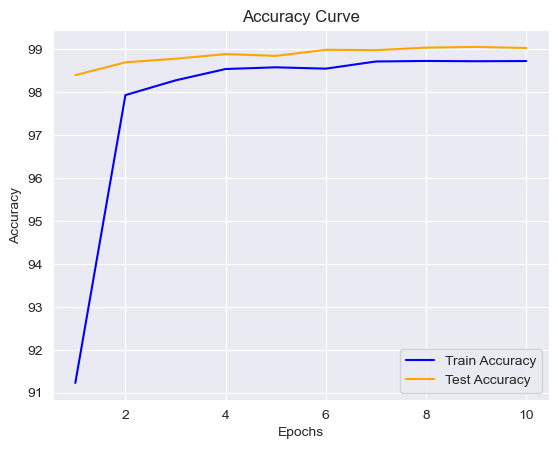

In [18]:
# 训练次数
epochs = range(1, len(fcd_train_losses) + 1)

# 绘制准确率曲线图
plt.plot(epochs, fcd_train_accs, label='Train Accuracy', color='blue')
plt.plot(epochs, fcd_test_accs, label='Test Accuracy', color='orange')

# 添加标签和标题
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy Curve')
plt.legend()
plt.grid(True)

# 显示图像
plt.show()

In [19]:
# 加载模型
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_fcd = FCNNModelWithDropout()
model_fcd.load_state_dict(torch.load('models/model_fcd.pth', map_location=device))
model_fcd.to(device)

FCNNModelWithDropout(
  (fc1): Linear(in_features=128, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=64, bias=True)
  (fc4): Linear(in_features=64, out_features=3, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)

In [20]:
# 初始化混淆矩阵和类别分类列表
label_dic = {0: 'separable states', 1: 'two-separable states', 2: 'entangled states'}
num_classes = len(label_dic)
conf_matrix = np.zeros((num_classes, num_classes))
class_correct = list(0. for i in range(num_classes))
class_total = list(0. for i in range(num_classes))

# 将模型设置为评估模式
model_fcd.eval()

# 在测试集上进行测试
with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model_fcd(inputs)
        _, predicted = torch.max(outputs, 1)
        c = (predicted == labels).squeeze()

        for i in range(len(labels)):
            label = labels[i]
            prediction = predicted[i]
            conf_matrix[label][prediction] += 1
            class_correct[label] += c[i].item()
            class_total[label] += 1

# 计算混淆矩阵的百分比
conf_matrix_percent_fcd = conf_matrix / np.sum(conf_matrix, axis=1, keepdims=True)

# 计算每个类别的准确率
class_accuracy_fcd = [100 * class_correct[i] / class_total[i] if class_total[i] > 0 else 0 for i in range(num_classes)]

# 计算精确率、召回率和 F1 值
precision_fcd = [conf_matrix[i][i] / np.sum(conf_matrix[:, i]) if np.sum(conf_matrix[:, i]) > 0 else 0 for i in
                 range(num_classes)]
recall_fcd = [conf_matrix[i][i] / np.sum(conf_matrix[i, :]) if np.sum(conf_matrix[i, :]) > 0 else 0 for i in
              range(num_classes)]
f1_fcd = [2 * precision_fcd[i] * recall_fcd[i] / (precision_fcd[i] + recall_fcd[i]) if precision_fcd[i] + recall_fcd[
    i] > 0 else 0 for i in range(num_classes)]


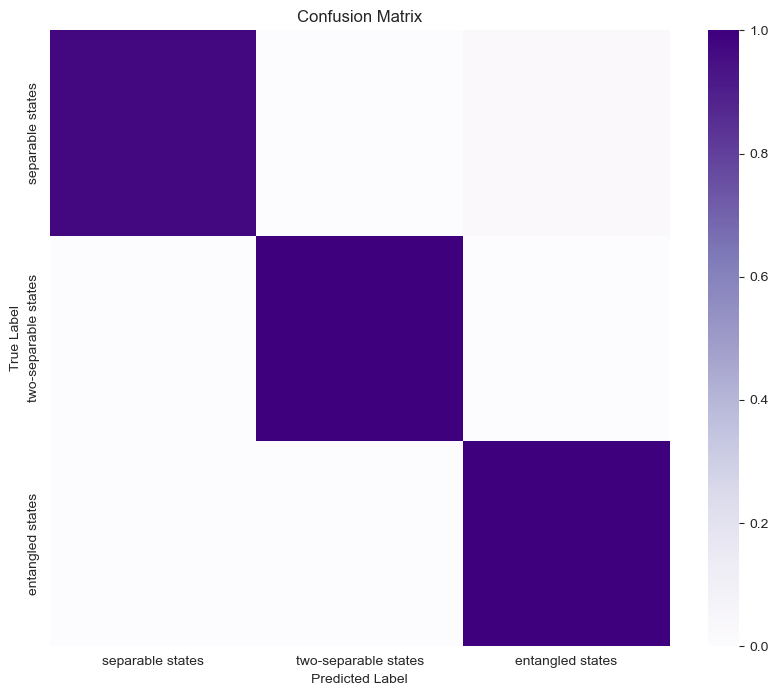

In [21]:
import seaborn as sns

# 绘制混淆矩阵
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_percent_fcd, annot=False, cmap='Purples', fmt=".2f", xticklabels=label_dic.values(),
            yticklabels=label_dic.values())
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

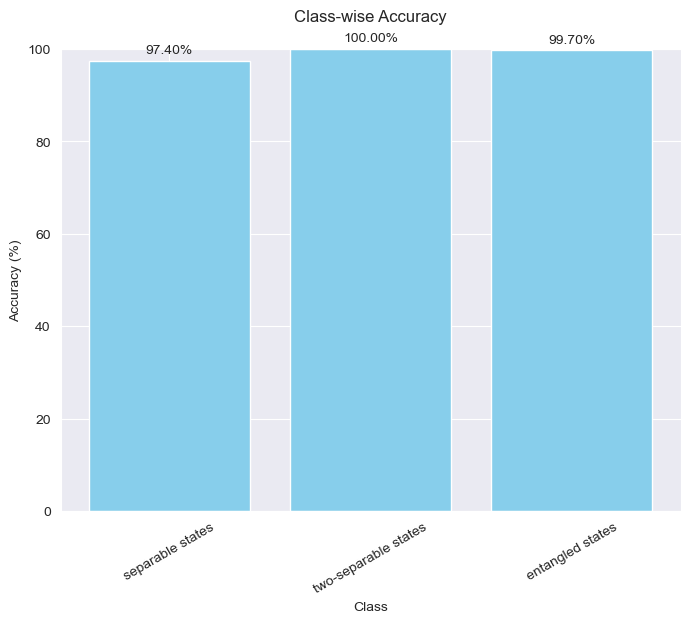

In [22]:
plt.figure(figsize=(8, 6))
bars = plt.bar(label_dic.values(), class_accuracy_fcd, color='skyblue')

# 在每个条形上方添加文本标签
for i, acc in enumerate(class_accuracy_fcd):
    plt.text(i, acc + 1, f'{acc:.2f}%', ha='center', va='bottom')

plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.title('Class-wise Accuracy', pad=20)
plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.show()

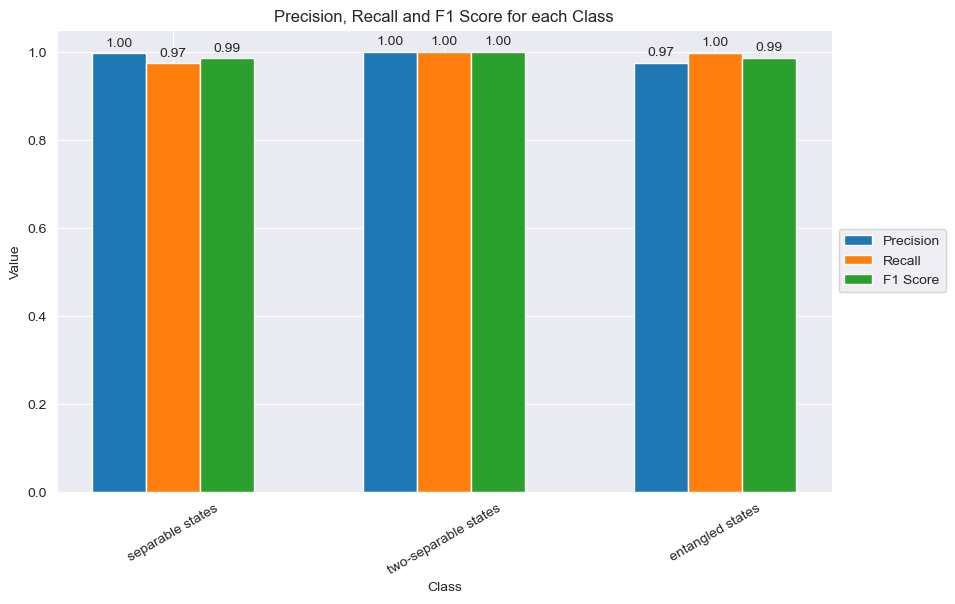

In [23]:
# 绘制精确率、召回率和 F1 值的条形图
x = np.arange(num_classes)
width = 0.2
label_dic = {0: 'separable states', 1: 'two-separable states', 2: 'entangled states'}
fig, ax = plt.subplots(figsize=(10, 6))
bars_precision = ax.bar(x - width, precision_fcd, width, label='Precision')
bars_recall = ax.bar(x, recall_fcd, width, label='Recall')
bars_f1 = ax.bar(x + width, f1_fcd, width, label='F1 Score')

ax.set_xlabel('Class')
ax.set_ylabel('Value')
ax.set_title('Precision, Recall and F1 Score for each Class')
ax.set_xticks(x)
ax.set_xticklabels(label_dic.values(), rotation=30)


# 添加数值标签
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate('%.2f' % height,
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')


autolabel(bars_precision)
autolabel(bars_recall)
autolabel(bars_f1)
# 移动图例到右边
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

# 卷积神经网络模型

## LeNet-5神经网络

对于该数据集，可以设计一个简单的LeNet-5结构，适用于处理8x8的复数矩阵。以下是LeNet-5结构示例：

1. **卷积层1(Convolutional Layer 1)**：
   - 输入大小：2x8x8（8x8的复数矩阵，2表示实部和虚部）
   - 卷积核大小：5x5
   - 卷积核数量：6
   - 激活函数：ReLU
   - 输出大小：4x4x6

2. **池化层1(Pooling Layer 1)**：
   - 池化类型：最大池化（Max Pooling）
   - 池化窗口大小：2x2
   - 输出大小：6x2x2

3. **卷积层2(Convolutional Layer 2)**：
   - 输入大小：6x2x2
   - 卷积核大小：2x2
   - 卷积核数量：16
   - 激活函数：ReLU
   - 输出大小：16x1x1

4. **池化层2(Pooling Layer 2)**：
   - 池化类型：最大池化（Max Pooling）
   - 池化窗口大小：1x1
   - 输出大小：16x1x1

5. **全连接层1(Fully Connected Layer 1)**：
   - 输入大小：16x1x1
   - 输出大小：120
   - 激活函数：ReLU

6. **全连接层2(Fully Connected Layer 2)**：
   - 输入大小：120
   - 输出大小：84
   - 激活函数：ReLU

7. **输出层(Output Layer)**：
   - 输入大小：84
   - 输出大小：3（对应三个类别）


In [24]:
import torch
import torch.nn as nn
import torch.optim as optim


class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        # Define the layers
        self.conv1 = nn.Conv2d(in_channels=2, out_channels=6, kernel_size=5, stride=1, padding=0)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)  # 最大池化层
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=2, stride=1, padding=0)
        self.pool2 = nn.MaxPool2d(kernel_size=1, stride=1)  # 最大池化层
        self.fc1 = nn.Linear(16 * 1 * 1, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 3)  # Three classes

    def forward(self, x):
        # Apply convolutional layers with ReLU activation and max pooling
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        # Flatten the output for fully connected layers
        # x = torch.flatten(x, 1)  # 将输入展平成一维张量
        x = x.view(-1, 16 * 1 * 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [25]:
# from tqdm import tqdm
# import torch.optim as optim

# 实例化模型
model_le = LeNet5()

# 定义损失函数和优化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_le.parameters(), lr=0.001)

# 训练模型
num_epochs = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_le.to(device)
model_le.train()

# 将每次训练的训练误差和测试误差存储在这两个列表里，后面绘制误差变化折线图用
le_train_losses, le_test_losses, le_train_accs, le_test_accs = [], [], [], []

print('Start training')
for epoch in range(num_epochs):
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    # for inputs, labels in tqdm(train_dataloader, desc=f'Epoch {epoch + 1}/{num_epochs}', leave=False):
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_le(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    # 每次学完一遍数据集，都进行以下测试操作
    model_le.eval()
    test_loss = 0.0
    correct_test = 0
    total_test = 0
    with torch.no_grad():
        # for inputs, labels in tqdm(test_dataloader, desc='Test', leave=False):
        for inputs, labels in test_dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_le(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(train_dataset)
    train_acc = 100. * correct_train / total_train
    test_loss = test_loss / len(test_dataset)
    test_acc = 100. * correct_test / total_test

    # 恢复Dropout
    model_le.train()

    # 将训练误差和测试误差存在两个列表里，后面绘制误差变化折线图用
    le_train_losses.append(train_loss)
    le_test_losses.append(test_loss)
    le_train_accs.append(train_acc)
    le_test_accs.append(test_acc)

    print("Number: {}/{}  ".format(epoch + 1, num_epochs),
          "Train Loss: {:.4f}  ".format(train_loss),
          "Test Loss: {:.4f}  ".format(test_loss),
          "Model Test Accuracy: {:.3f}%".format(test_acc))

print('Finished Training')

Start training
Number: 1/10   Train Loss: 0.3149   Test Loss: 0.0898   Model Test Accuracy: 97.383%
Number: 2/10   Train Loss: 0.0885   Test Loss: 0.0697   Model Test Accuracy: 98.017%
Number: 3/10   Train Loss: 0.0737   Test Loss: 0.0617   Model Test Accuracy: 98.342%
Number: 4/10   Train Loss: 0.0671   Test Loss: 0.0565   Model Test Accuracy: 98.508%
Number: 5/10   Train Loss: 0.0629   Test Loss: 0.0537   Model Test Accuracy: 98.475%
Number: 6/10   Train Loss: 0.0604   Test Loss: 0.0595   Model Test Accuracy: 98.225%
Number: 7/10   Train Loss: 0.0595   Test Loss: 0.0534   Model Test Accuracy: 98.575%
Number: 8/10   Train Loss: 0.0584   Test Loss: 0.0607   Model Test Accuracy: 98.292%
Number: 9/10   Train Loss: 0.0570   Test Loss: 0.0517   Model Test Accuracy: 98.658%
Number: 10/10   Train Loss: 0.0564   Test Loss: 0.0513   Model Test Accuracy: 98.625%
Finished Training


In [26]:
# 保存模型
torch.save(model_le.state_dict(), 'models/model_le.pth', _use_new_zipfile_serialization=False)

### 验证模型效果

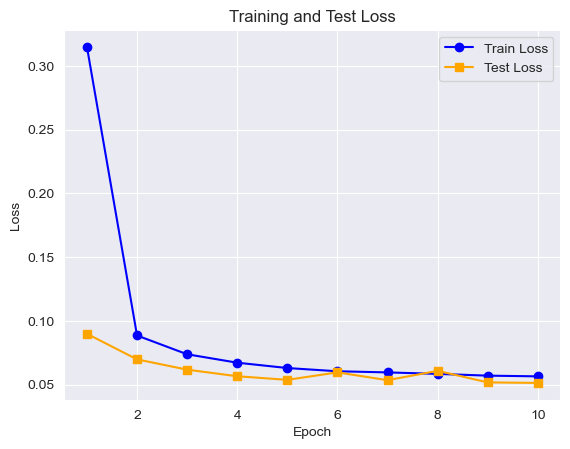

In [27]:
# 训练次数
epochs = range(1, len(le_train_losses) + 1)

# 绘制训练误差和测试误差随学习次数增加的变化曲线
# plt.figure(figsize=(10, 5))
plt.plot(epochs, le_train_losses, label='Train Loss', color='blue', marker='o')
plt.plot(epochs, le_test_losses, label='Test Loss', color='orange', marker='s')

# 添加标签和标题
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Test Loss')
plt.legend()
plt.grid(True)

# 设置 x 轴刻度为每个 epoch 单位
# plt.xticks(range(1, len(fc_train_losses) + 1))

plt.show()

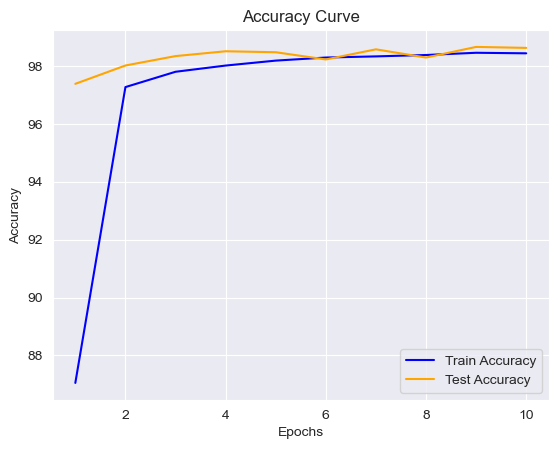

In [28]:
# 训练次数
epochs = range(1, len(le_train_losses) + 1)

# 绘制准确率曲线图
plt.plot(epochs, le_train_accs, label='Train Accuracy', color='blue')
plt.plot(epochs, le_test_accs, label='Test Accuracy', color='orange')

# 添加标签和标题
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy Curve')
plt.legend()
plt.grid(True)

# 显示图像
plt.show()

In [29]:
# 加载模型
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_le = LeNet5()
model_le.load_state_dict(torch.load('models/model_le.pth', map_location=device))
model_le.to(device)

LeNet5(
  (conv1): Conv2d(2, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(2, 2), stride=(1, 1))
  (pool2): MaxPool2d(kernel_size=1, stride=1, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=16, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=3, bias=True)
)

In [30]:
# 初始化混淆矩阵和类别分类列表
label_dic = {0: 'separable states', 1: 'two-separable states', 2: 'entangled states'}
num_classes = len(label_dic)
conf_matrix = np.zeros((num_classes, num_classes))
class_correct = list(0. for i in range(num_classes))
class_total = list(0. for i in range(num_classes))

# 将模型设置为评估模式
model_le.eval()

# 在测试集上进行测试
with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model_le(inputs)
        _, predicted = torch.max(outputs, 1)
        c = (predicted == labels).squeeze()

        for i in range(len(labels)):
            label = labels[i]
            prediction = predicted[i]
            conf_matrix[label][prediction] += 1
            class_correct[label] += c[i].item()
            class_total[label] += 1

# 计算混淆矩阵的百分比
conf_matrix_percent_le = conf_matrix / np.sum(conf_matrix, axis=1, keepdims=True)

# 计算每个类别的准确率
class_accuracy_le = [100 * class_correct[i] / class_total[i] if class_total[i] > 0 else 0 for i in range(num_classes)]

# 计算精确率、召回率和 F1 值
precision_le = [conf_matrix[i][i] / np.sum(conf_matrix[:, i]) if np.sum(conf_matrix[:, i]) > 0 else 0 for i in
                range(num_classes)]
recall_le = [conf_matrix[i][i] / np.sum(conf_matrix[i, :]) if np.sum(conf_matrix[i, :]) > 0 else 0 for i in
             range(num_classes)]
f1_le = [
    2 * precision_le[i] * recall_le[i] / (precision_le[i] + recall_le[i]) if precision_le[i] + recall_le[i] > 0 else 0
    for i in range(num_classes)]

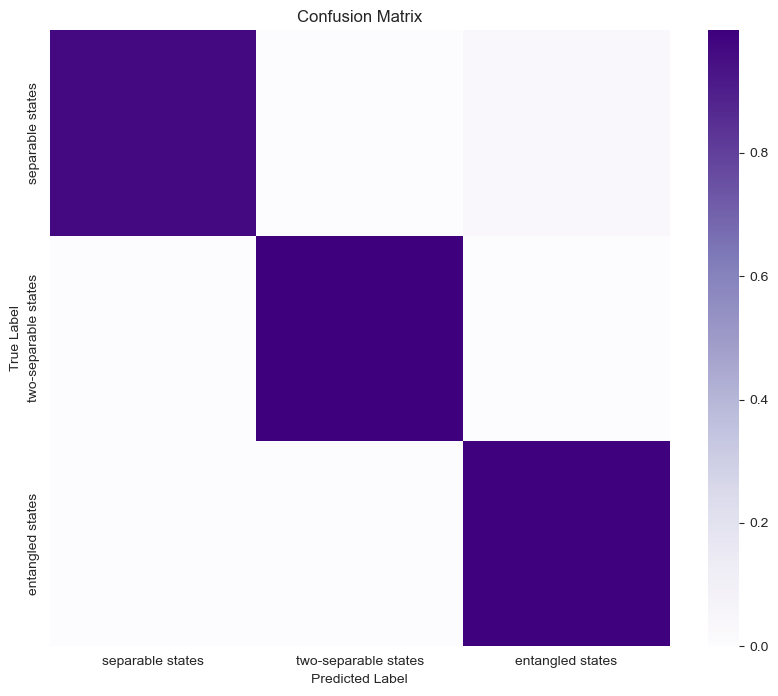

In [31]:
import seaborn as sns

# 绘制混淆矩阵
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_percent_le, annot=False, cmap='Purples', fmt=".2f", xticklabels=label_dic.values(),
            yticklabels=label_dic.values())
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

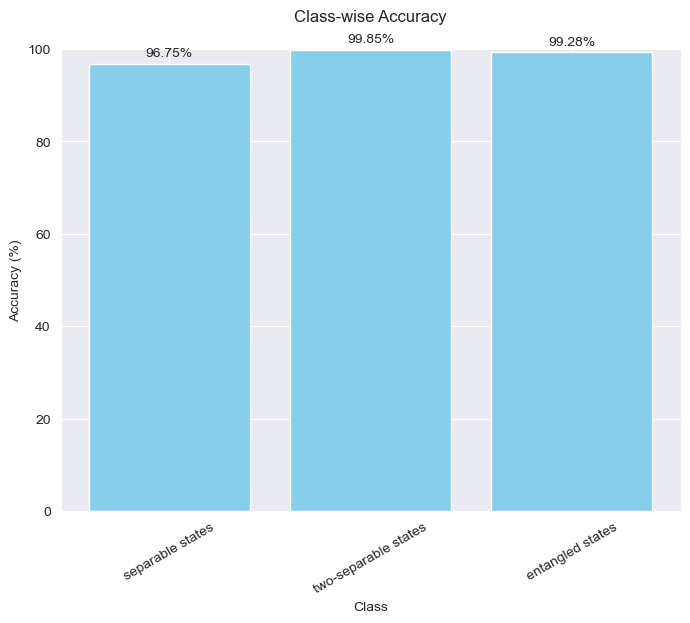

In [32]:
plt.figure(figsize=(8, 6))
bars = plt.bar(label_dic.values(), class_accuracy_le, color='skyblue')

# 在每个条形上方添加文本标签
for i, acc in enumerate(class_accuracy_le):
    plt.text(i, acc + 1, f'{acc:.2f}%', ha='center', va='bottom')

plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.title('Class-wise Accuracy', pad=20)
plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.show()

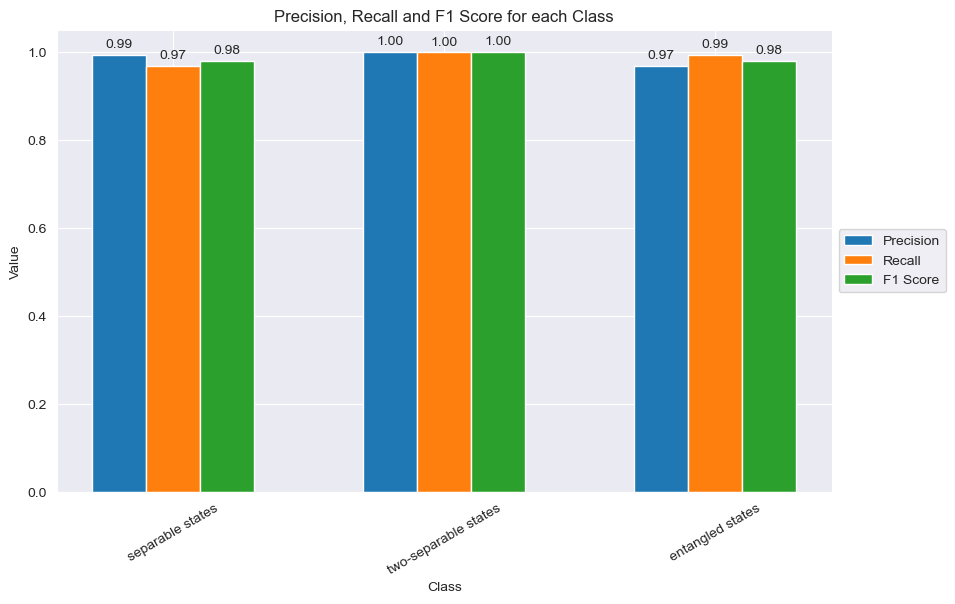

In [33]:
# 绘制精确率、召回率和 F1 值的条形图
x = np.arange(num_classes)
width = 0.2
label_dic = {0: 'separable states', 1: 'two-separable states', 2: 'entangled states'}
fig, ax = plt.subplots(figsize=(10, 6))
bars_precision = ax.bar(x - width, precision_le, width, label='Precision')
bars_recall = ax.bar(x, recall_le, width, label='Recall')
bars_f1 = ax.bar(x + width, f1_le, width, label='F1 Score')

ax.set_xlabel('Class')
ax.set_ylabel('Value')
ax.set_title('Precision, Recall and F1 Score for each Class')
ax.set_xticks(x)
ax.set_xticklabels(label_dic.values(), rotation=30)


# 添加数值标签
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate('%.2f' % height,
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')


autolabel(bars_precision)
autolabel(bars_recall)
autolabel(bars_f1)
# 移动图例到右边
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()